# Predicting movie ratings and making recommendations using the MovieLens dataset 

# 1.Introduction and dataset
Movie recommendation systems help users discover movies based on their interests and previous preferences. However, different recommendation approaches represent relationships between movies in different ways.

## 1.1 Import Data

In [2]:
from pathlib import Path
import pandas as pd

data_dir = Path("data/ml-32m")

movies = pd.read_csv(data_dir / "movies.csv")
ratings = pd.read_csv(data_dir / "ratings.csv")

print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Users:", ratings["userId"].nunique())

genres = (
    movies.loc[movies["genres"] != "(no genres listed)", "genres"]
    .dropna()
    .str.split("|")
    .explode()
    .unique()
)
print("Genres:", len(genres))

print("\nMovies preview:")
display(movies.head())

print("\nRatings preview:")
display(ratings.head())

print("\nMissing values:")
print("Movies:", movies.isna().sum().to_dict())
print("Ratings:", ratings.isna().sum().to_dict())

Movies: (87585, 3)
Ratings: (32000204, 4)
Users: 200948
Genres: 19

Movies preview:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



Ratings preview:


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858



Missing values:
Movies: {'movieId': 0, 'title': 0, 'genres': 0}
Ratings: {'userId': 0, 'movieId': 0, 'rating': 0, 'timestamp': 0}


## 1.2 Data Analysis and Versualization

The MovieLens 32M dataset contains 87,585 movies and 32,000,204 user ratings. The movie metadata includes movie titles and genres, while the ratings data contains anonymous user IDs, movie IDs, ratings, and timestamps.

No missing values were found in the inspected columns of either dataset. The following visualizations explore movie genres, rating patterns, and the temporal distribution of user ratings.

### 1.2.1 Genre Distribution

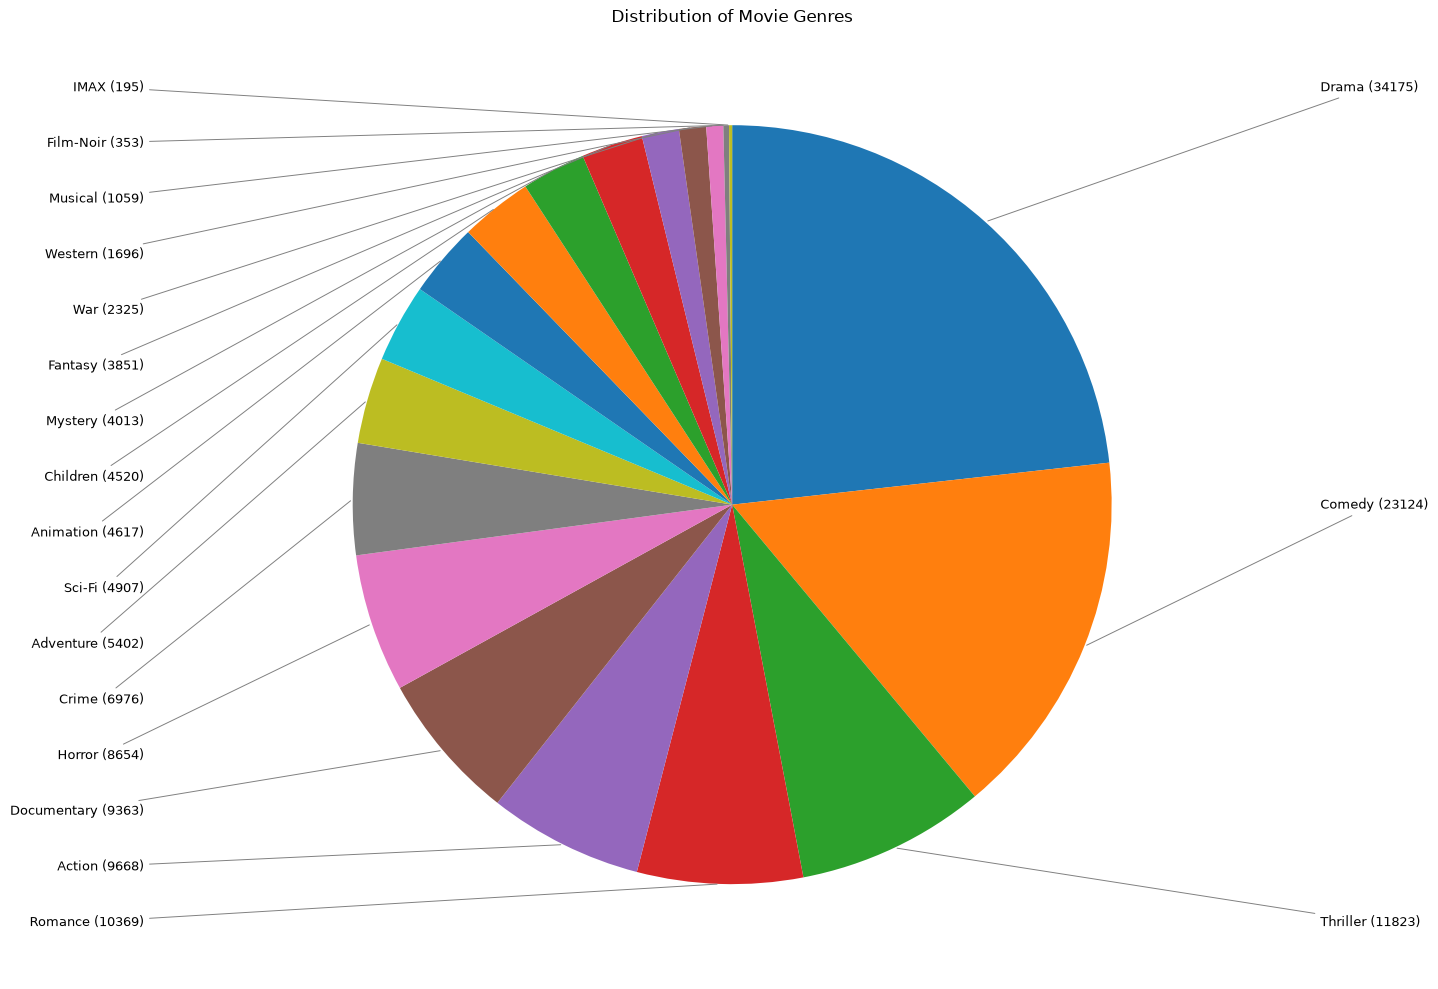

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

data_dir = Path("data/ml-32m")

movies = pd.read_csv(data_dir / "movies.csv")
ratings = pd.read_csv(data_dir / "ratings.csv")

# 1. Movie genres: count movies in each genre
# Count each genre separately
genre_counts = Counter()

for genres in movies["genres"].dropna():
    if genres != "(no genres listed)":
        genre_counts.update(genres.split("|"))

genre_counts = pd.Series(genre_counts).sort_values(ascending=False)

# Create pie chart
fig, ax = plt.subplots(figsize=(13, 10))

wedges, _ = ax.pie(
    genre_counts.values,
    startangle=90,
    counterclock=False,
    labels=None
)

# Calculate the original positions of all labels
labels_info = []

for i, wedge in enumerate(wedges):
    angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)
    labels_info.append({
        "name": genre_counts.index[i],
        "count": genre_counts.iloc[i],
        "x": np.cos(angle),
        "y": np.sin(angle)
    })

# Place labels on both sides, spacing them vertically
for side in [-1, 1]:
    items = sorted(
        [item for item in labels_info if item["x"] * side > 0],
        key=lambda item: item["y"]
    )

    # Evenly distribute label positions vertically
    if len(items) > 1:
        y_positions = np.linspace(-1.1, 1.1, len(items))
    else:
        y_positions = [0] if items else []

    for item, label_y in zip(items, y_positions):
        ax.annotate(
            f'{item["name"]} ({item["count"]})',
            xy=(item["x"], item["y"]),
            xytext=(1.55 * side, label_y),
            ha="left" if side > 0 else "right",
            va="center",
            fontsize=9,
            arrowprops={
                "arrowstyle": "-",
                "color": "gray",
                "lw": 0.7
            }
        )

ax.set_title("Distribution of Movie Genres")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

### 1.2.2 Rating distribution

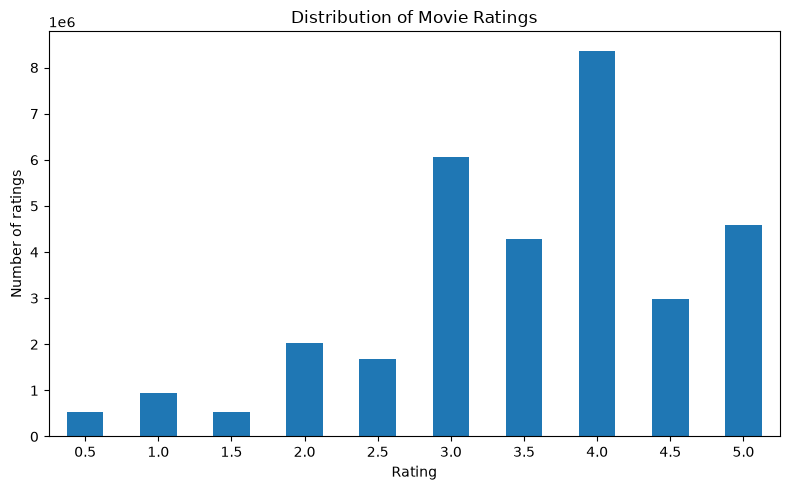

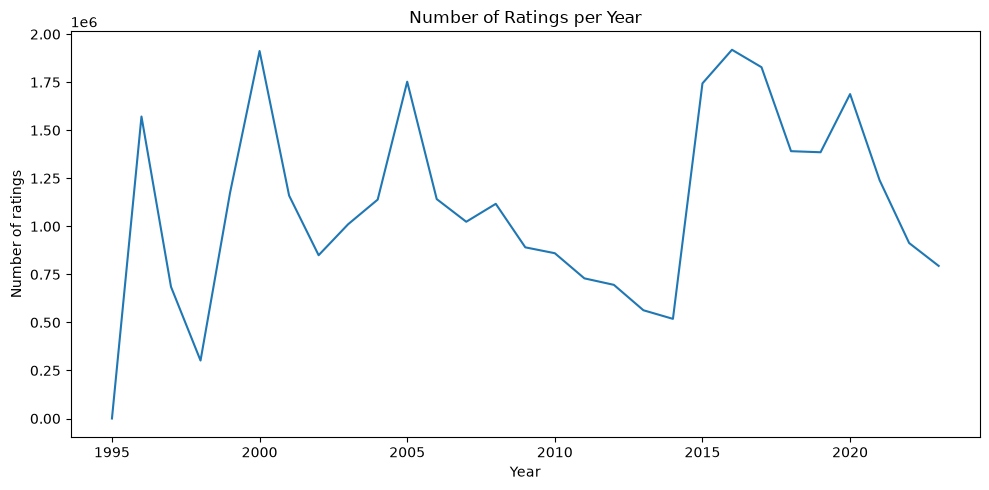

In [7]:
# Rating distribution
rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
rating_counts.plot.bar()
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Distribution of Movie Ratings")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Number of ratings per year
ratings["year"] = pd.to_datetime(
    ratings["timestamp"], unit="s", utc=True
).dt.year

year_counts = ratings["year"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
year_counts.plot()
plt.xlabel("Year")
plt.ylabel("Number of ratings")
plt.title("Number of Ratings per Year")
plt.tight_layout()
plt.show()

### 1.2.3 Peferences by rating

In [9]:
# Calculate each user's overall rating statistics
user_stats = ratings.groupby("userId")["rating"].agg(["mean", "count"])
eligible_users = user_stats[user_stats["count"] >= 100]
high_users = eligible_users.nlargest(1000, "mean").index
low_users = eligible_users.nsmallest(1000, "mean").index
print("High-rating users:", len(high_users))
print("Low-rating users:", len(low_users))
print("\nOverall mean rating:")
print("High-rating group:", round(user_stats.loc[high_users, "mean"].mean(), 3))
print("Low-rating group:", round(user_stats.loc[low_users, "mean"].mean(), 3))

High-rating users: 1000
Low-rating users: 1000

Overall mean rating:
High-rating group: 4.722
Low-rating group: 2.086


In [10]:
selected_users = set(high_users) | set(low_users)
selected_ratings = ratings[
    ratings["userId"].isin(selected_users)
].copy()
selected_ratings = selected_ratings.merge(
    movies[["movieId", "genres"]],
    on="movieId",
    how="left"
)
selected_ratings["user_group"] = np.where(
    selected_ratings["userId"].isin(high_users),    
"High-rating users",    
"Low-rating users"
)
selected_ratings["user_mean"] = (
    selected_ratings["userId"].map(user_stats["mean"])
)
selected_ratings["centered_rating"] = (
    selected_ratings["rating"] - selected_ratings["user_mean"]
)
selected_ratings["genre_list"] = (
    selected_ratings["genres"]    
.fillna("")    
.str.split("|")
)
genre_ratings = selected_ratings.explode("genre_list")
genre_ratings = genre_ratings[
    genre_ratings["genre_list"].notna()    
& (genre_ratings["genre_list"] != "")    
& (genre_ratings["genre_list"] != "(no genres listed)")
].copy()
print("Selected rating records:", len(selected_ratings))
print("Records after genre expansion:", len(genre_ratings))

Selected rating records: 736630
Records after genre expansion: 1987044


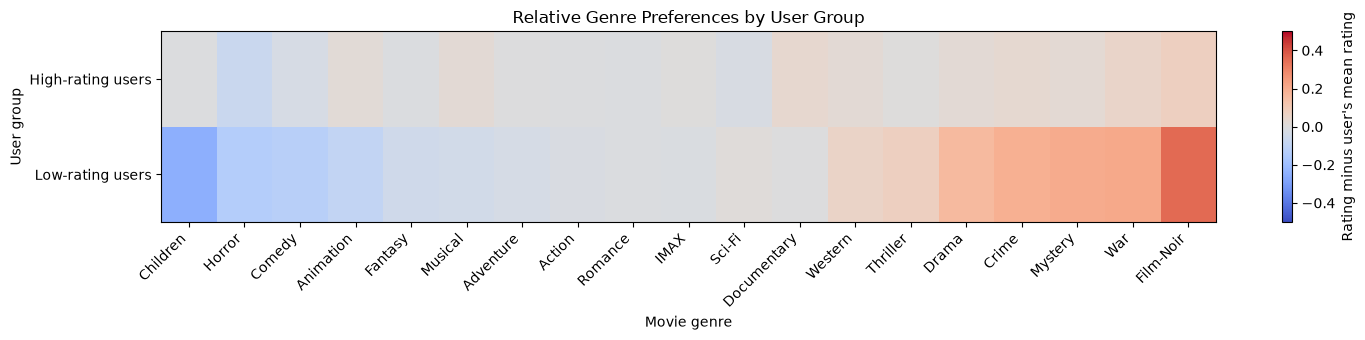

In [11]:
centered_mean = (
    genre_ratings
    .groupby(["user_group", "genre_list"])["centered_rating"]
    .mean()
    .unstack()
)

# Sort genres by their overall relative preference
genre_order_centered = (
    genre_ratings.groupby("genre_list")["centered_rating"]
    .mean()
    .sort_values()
    .index
)

centered_mean = centered_mean.reindex(
    columns=genre_order_centered
)

fig, ax = plt.subplots(figsize=(15, 3.5))

im = ax.imshow(
    centered_mean.to_numpy(),
    aspect="auto",
    cmap="coolwarm",
    interpolation="nearest",
    vmin=-0.5,
    vmax=0.5
)

ax.set_yticks(range(len(centered_mean.index)))
ax.set_yticklabels(centered_mean.index)

ax.set_xticks(range(len(centered_mean.columns)))
ax.set_xticklabels(
    centered_mean.columns,
    rotation=45,
    ha="right"
)

ax.set_title("Relative Genre Preferences by User Group")
ax.set_xlabel("Movie genre")
ax.set_ylabel("User group")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Rating minus user's mean rating")

plt.tight_layout()
plt.show()

### 1.2.4 Peferences by each genre

In [12]:
genre_fan_groups = {}

all_genres = sorted({
    genre
    for genres in movies["genres"].dropna()
    if genres != "(no genres listed)"
    for genre in genres.split("|")
})

for target_genre in all_genres:
    target_movie_ids = movies.loc[
        movies["genres"].fillna("").apply(
            lambda genres: target_genre in genres.split("|")
        ),
        "movieId"
    ]

    target_ratings = ratings[
        ratings["movieId"].isin(target_movie_ids)
    ].copy()

    target_ratings["user_mean"] = (
        target_ratings["userId"].map(user_stats["mean"])
    )

    target_ratings["centered_rating"] = (
        target_ratings["rating"] - target_ratings["user_mean"]
    )

    fan_stats = (
        target_ratings.groupby("userId")
        .agg(
            genre_mean=("centered_rating", "mean"),
            genre_rating_count=("rating", "count")
        )
    )

    eligible_fans = fan_stats[
        fan_stats["genre_rating_count"] >= 10
    ]

    top_fans = eligible_fans.nlargest(
        100, "genre_mean"
    ).index

    genre_fan_groups[target_genre] = top_fans

    print(
        f"{target_genre}: {len(top_fans)} users; "
        f"mean relative rating = "
        f"{eligible_fans.loc[top_fans, 'genre_mean'].mean():.3f}"
    )

Action: 100 users; mean relative rating = 1.308
Adventure: 100 users; mean relative rating = 1.292
Animation: 100 users; mean relative rating = 1.489
Children: 100 users; mean relative rating = 1.440
Comedy: 100 users; mean relative rating = 1.125
Crime: 100 users; mean relative rating = 1.321
Documentary: 100 users; mean relative rating = 1.366
Drama: 100 users; mean relative rating = 1.197
Fantasy: 100 users; mean relative rating = 1.253
Film-Noir: 100 users; mean relative rating = 1.515
Horror: 100 users; mean relative rating = 1.191
IMAX: 100 users; mean relative rating = 1.312
Musical: 100 users; mean relative rating = 1.231
Mystery: 100 users; mean relative rating = 1.228
Romance: 100 users; mean relative rating = 1.245
Sci-Fi: 100 users; mean relative rating = 1.296
Thriller: 100 users; mean relative rating = 1.206
War: 100 users; mean relative rating = 1.299
Western: 100 users; mean relative rating = 1.091


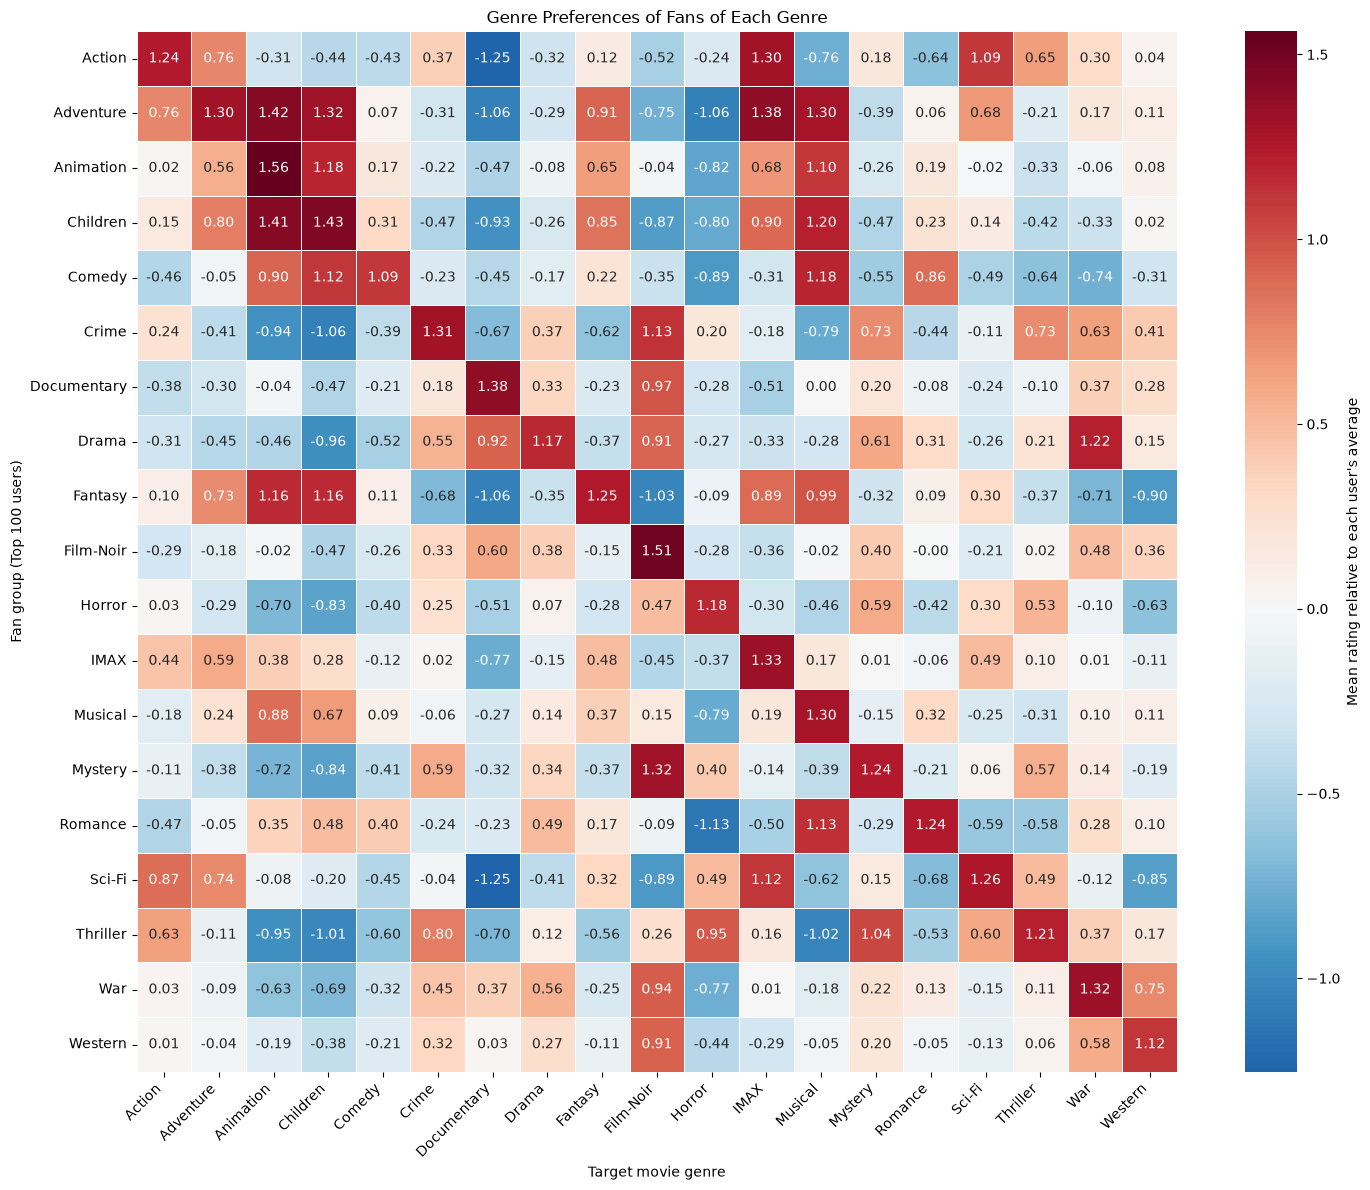

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Calculate each user's mean-centered rating for every genre
genre_preference = pd.DataFrame(
    index=all_genres,
    columns=all_genres,
    dtype=float
)

for fan_genre in all_genres:
    fan_ids = genre_fan_groups[fan_genre]

    for target_genre in all_genres:
        target_movie_ids = movies.loc[
            movies["genres"].fillna("").apply(
                lambda genres: target_genre in genres.split("|")
            ),
            "movieId"
        ]

        target_ratings = ratings[
            ratings["userId"].isin(fan_ids)
            & ratings["movieId"].isin(target_movie_ids)
        ].copy()

        target_ratings["user_mean"] = (
            target_ratings["userId"].map(user_stats["mean"])
        )

        target_ratings["centered_rating"] = (
            target_ratings["rating"] - target_ratings["user_mean"]
        )

        genre_preference.loc[fan_genre, target_genre] = (
            target_ratings["centered_rating"].mean()
        )

# 2. Plot the 19 x 19 heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    genre_preference,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Mean rating relative to each user's average"
    }
)

plt.title("Genre Preferences of Fans of Each Genre")
plt.xlabel("Target movie genre")
plt.ylabel("Fan group (Top 100 users)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Predicting User Movie Ratings

The goal of this part is to predict how a user would rate a movie based on historical user–movie ratings.

The target variable is the numerical rating given to a movie by a user, ranging from 0.5 to 5.0 in the MovieLens 32M dataset.

We compare four models with different assumptions and levels of complexity:

1. **Ordinary Linear Regression:** A baseline linear model using user and movie identities as features.
2. **Ridge Regression:** A linear model with L2 regularisation to reduce overfitting.
3. **Bias Model:** A model that combines the global average rating with user-specific and movie-specific biases.
4. **Singular Value Decomposition (SVD):** A matrix factorisation approach that learns latent representations of users and movies.

The models are evaluated on a held-out test set using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (\(R^2\)). This allows us to compare their predictive accuracy and discuss the trade-offs between model simplicity and complexity.

## 2.1 Data Preparation

We use the user ID, movie ID, and rating columns from the ratings dataset. The data are randomly split into training and test sets using an 80:20 ratio.

The models are fitted using the training set, while the test set is reserved for evaluating predictions on ratings that were not used during training. A fixed random seed ensures that the split can be reproduced.

This random split evaluates predictions for users and movies that may already appear in the training data. Therefore, it does not directly measure performance on entirely new users or movies.

In [14]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

# Load ratings
ratings = pd.read_csv("data/ml-32m/ratings.csv")

X = ratings[["userId", "movieId"]]
y = ratings["rating"]

# Random split by rating records: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)


Training set: (25600163, 2)
Test set: (6400041, 2)


## 2.2 Models

### 2.2.1：Ordinary Linear Regression

Ordinary linear regression is used as a baseline model for predicting movie ratings. User IDs and movie IDs are one-hot encoded so that the model can learn user-specific and movie-specific effects without treating the identifiers as continuous numerical variables.

Unlike Ridge regression, ordinary linear regression does not apply L2 regularization. Comparing the two models helps us examine the effect of regularization on prediction performance.

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# One-hot encode user and movie IDs
preprocessor_lr = ColumnTransformer(
    transformers=[
        (
            "ids",
            OneHotEncoder(
                handle_unknown="ignore",
                dtype="float32"
            ),
            ["userId", "movieId"]
        )
    ]
)

# Build and train the model
linear_model = Pipeline([
    ("preprocessor", preprocessor_lr),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

# Predict ratings on the test set
linear_pred = linear_model.predict(X_test)

# Evaluate performance
linear_results = {
    "Model": "Ordinary Linear Regression",
    "MAE": mean_absolute_error(y_test, linear_pred),
    "RMSE": root_mean_squared_error(y_test, linear_pred),
    "R2": r2_score(y_test, linear_pred)
}

print(linear_results)

{'Model': 'Ordinary Linear Regression', 'MAE': 0.6493937300152147, 'RMSE': 0.8553466169914112, 'R2': 0.3472601490937183}


### 2.2.2 Ridge Regression

In [16]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "ids",
            OneHotEncoder(handle_unknown="ignore"),
            ["userId", "movieId"]
        )
    ]
)

ridge_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0, solver="lsqr"))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_results = {
    "Model": "Ridge Regression",
    "MAE": mean_absolute_error(y_test, ridge_pred),
    "RMSE": root_mean_squared_error(y_test, ridge_pred),
    "R2": r2_score(y_test, ridge_pred)
}

print(ridge_results)


{'Model': 'Ridge Regression', 'MAE': 0.6502377001767801, 'RMSE': 0.8549893509332136, 'R2': 0.34780531543073756}


### 2.2.3 Bias Model

In [17]:

# Build a training-only table
train_df = X_train.copy()
train_df["rating"] = y_train

global_mean = train_df["rating"].mean()

# Regularization strengths
lambda_user = 10
lambda_movie = 10

# Initialize biases
user_bias = pd.Series(dtype=float)
movie_bias = pd.Series(dtype=float)

# Alternate updates
for _ in range(10):
    # Update user biases
    residual_user = (
        train_df["rating"]
        - global_mean
        - train_df["movieId"].map(movie_bias).fillna(0)
    )

    user_stats = pd.DataFrame({
        "userId": train_df["userId"],
        "residual": residual_user
    }).groupby("userId")["residual"].agg(["sum", "count"])

    user_bias = (
        user_stats["sum"] /
        (user_stats["count"] + lambda_user)
    )

    # Update movie biases
    residual_movie = (
        train_df["rating"]
        - global_mean
        - train_df["userId"].map(user_bias).fillna(0)
    )

    movie_stats = pd.DataFrame({
        "movieId": train_df["movieId"],
        "residual": residual_movie
    }).groupby("movieId")["residual"].agg(["sum", "count"])

    movie_bias = (
        movie_stats["sum"] /
        (movie_stats["count"] + lambda_movie)
    )

# Predict test ratings
bias_pred = (
    global_mean
    + X_test["userId"].map(user_bias).fillna(0).to_numpy()
    + X_test["movieId"].map(movie_bias).fillna(0).to_numpy()
)

bias_results = {
    "Model": "User / Movie Bias",
    "MAE": mean_absolute_error(y_test, bias_pred),
    "RMSE": root_mean_squared_error(y_test, bias_pred),
    "R2": r2_score(y_test, bias_pred)
}

print(bias_results)


{'Model': 'User / Movie Bias', 'MAE': 0.6501895952727289, 'RMSE': 0.8551866311038324, 'R2': 0.3475043060144384}


### 2.2.4 SVD Model

Singular Value Decomposition (SVD) is a matrix factorisation approach commonly used in collaborative filtering. It represents users and movies using lower-dimensional latent factor vectors, allowing the model to capture patterns in rating behaviour that cannot be explained by user or movie averages alone.

In this project, the SVD model learns latent representations from the training ratings and uses them to predict user–movie ratings. Compared with linear regression and the user–movie bias model, SVD can capture more complex interactions between users and movies.

The model is implemented using the `SVD` algorithm from the Surprise library. Its predictive performance is evaluated on the same held-out test set as the other models, using MAE, RMSE, and \(R^2\).

In [18]:
from surprise import Dataset, Reader, SVD, accuracy
# Define the rating scale
reader = Reader(rating_scale=(0.5, 5.0))
# Build the training set from observed ratings only
train_surprise = Dataset.load_from_df(
    train_df[["userId", "movieId", "rating"]],
    reader
).build_full_trainset()
# Train matrix factorization model
svd_model = SVD(
    n_factors=20,
    n_epochs=20,
    lr_all=0.005,
    reg_all=0.02,
    random_state=42
)
svd_model.fit(train_surprise)

In [20]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import numpy as np

# Predict ratings for the test set
testset = [
    (user_id, movie_id, rating)
    for user_id, movie_id, rating in zip(
        X_test["userId"],
        X_test["movieId"],
        y_test
    )
]

predictions = svd_model.test(testset)

# Extract true and predicted ratings
y_true = np.array([pred.r_ui for pred in predictions])
y_pred = np.array([pred.est for pred in predictions])

# Calculate evaluation metrics
svd_mae = mean_absolute_error(y_true, y_pred)
svd_rmse = root_mean_squared_error(y_true, y_pred)
svd_r2 = r2_score(y_true, y_pred)

svd_results = {
    "Model": "SVD",
    "MAE": svd_mae,
    "RMSE": svd_rmse,
    "R2": svd_r2
}

print(svd_results)


{'Model': 'SVD', 'MAE': 0.5847251075959464, 'RMSE': 0.7775559237381716, 'R2': 0.4605898520627999}


## 2.3 Model Evaluation and Comparison

The three baseline models—Ordinary Linear Regression, Ridge Regression, and the User–Movie Bias Model—achieve very similar results, with MAE values around 0.65 and R² values around 0.35. This suggests that, in this setting, adding L2 regularisation or using an explicit user–movie bias formulation does not substantially improve rating prediction over ordinary linear regression.

In contrast, the SVD model performs considerably better, achieving an MAE of 0.5847, an RMSE of 0.7776, and an R² of 0.4606. Compared with Ordinary Linear Regression, SVD reduces MAE by approximately 10% and RMSE by approximately 9%, while increasing R² by about 0.11.

These results suggest that learning latent user and movie representations captures additional patterns in rating behaviour that the simpler baseline models do not capture. However, the evaluation uses a random train–test split, so the results primarily reflect prediction for users and movies represented in the training data. They do not establish how well the models would perform for entirely new users or movies.

In [21]:
results = pd.DataFrame([
    linear_results,
    ridge_results,
    bias_results,
    svd_results
]).set_index("Model")

display(results.round(4))

,MAE,RMSE,R2
Model,,,
Ordinary Linear Regression,0.6494,0.8553,0.3473
Ridge Regression,0.6502,0.8550,0.3478
User / Movie Bias,0.6502,0.8552,0.3475
SVD,0.5847,0.7776,0.4606


# 3. Movie Recommendation

## 3.1 From Rating Prediction to Movie Recommendation

So far, we have trained models to predict how a user might rate a particular movie. But can we learn something more from the data? Instead of predicting a single rating, can we use the patterns in millions of ratings to discover what kinds of movies someone might enjoy?

Imagine a new user arrives, with no rating history in our database. We cannot directly apply the user-specific information learned by our rating prediction models. Nevertheless, we do have information about movies: their genres, how other users have rated them, and the patterns captured by our SVD model. Could these provide useful clues about the user's preferences?

To explore this question, we compare three ways of representing relationships between movies: genre-based similarity, rating-based similarity, and SVD-based similarity. We use a small collection of input movies as a proxy for a user's interests, then examine which other movies each method recommends.

## 3.2 Methods

To explore how different kinds of information can be used to recommend movies, we compare three methods. All three represent movies as feature vectors and use cosine similarity to measure the similarity between movies. However, the information encoded in these vectors differs between methods:

1. **Genre-based similarity:** represents each movie using its genres.
2. **Rating-based similarity:** represents each movie using the ratings it receives from different users.
3. **SVD-based similarity:** represents each movie using the latent factors learned by the SVD rating prediction model.

### Cosine Similarity

Cosine similarity measures the cosine of the angle between two non-zero vectors. It is defined as

$$
\operatorname{sim}(A,B)=
\frac{A\cdot B}{\|A\|\|B\|}
$$

A larger cosine similarity indicates that two vectors point in more similar directions. For non-negative feature vectors, the similarity ranges from 0 to 1. For vectors that contain negative values, such as SVD latent factor vectors, it can also be negative.

For a set of input movies, we calculate the similarity between each input movie and the candidate movies, then combine the scores to rank the candidates. The input movies themselves are excluded from the recommendations.

Although the three methods share the same similarity measure, they may produce different recommendations because they capture different aspects of the relationships between movies. The following sections describe how each representation is constructed.

### 3.2.1 Genre-based Similarity

The first method represents each movie using its genre labels. MovieLens provides a set of genres for each movie, such as Action, Comedy, Drama, and Sci-Fi.

We convert these labels into binary feature vectors using one-hot multi-label encoding: each feature corresponds to a genre, and a movie receives a value of 1 if it belongs to that genre and 0 otherwise. We then normalise the vectors and calculate cosine similarity between them.

This approach recommends movies with similar genre compositions. It is straightforward and interpretable, but it does not capture differences between movies within the same genre or learn from users' actual rating behaviour.

In [22]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer, normalize

# Copy the movie data
movies_rec = movies.copy()

# Split genres into lists
movies_rec["genre_list"] = movies_rec["genres"].apply(
    lambda x: (
        x.split("|")
        if pd.notna(x) and x != "(no genres listed)"
        else []
    )
)

# Convert genres into a sparse binary feature matrix
mlb = MultiLabelBinarizer(sparse_output=True)
genre_matrix = mlb.fit_transform(movies_rec["genre_list"])

# Normalize feature vectors for cosine similarity
genre_matrix = normalize(
    genre_matrix,
    norm="l2",
    axis=1
)

# Check the results
print("Number of movies:", len(movies_rec))
print("Number of genres:", len(mlb.classes_))
print("Genre matrix shape:", genre_matrix.shape)
print("Matrix type:", type(genre_matrix))
print("Number of non-zero entries:", genre_matrix.nnz)

Number of movies: 87585
Number of genres: 19
Genre matrix shape: (87585, 19)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Number of non-zero entries: 147090


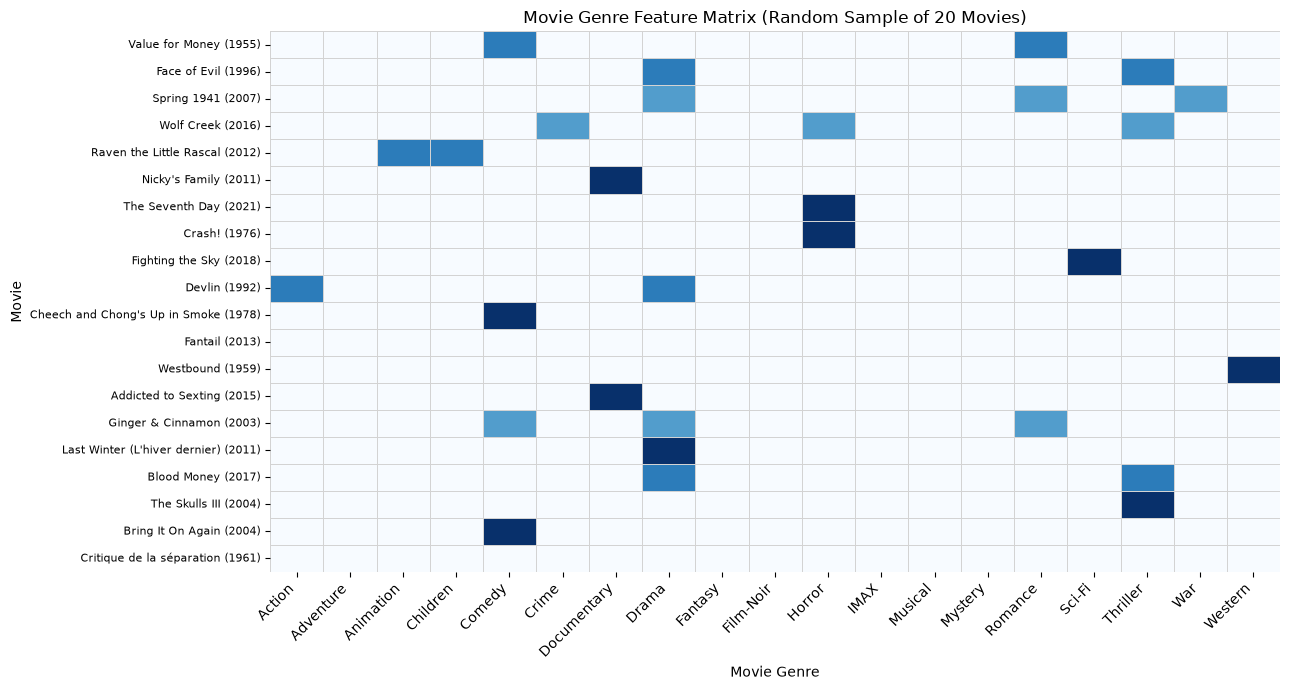

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Randomly sample 20 movies
sample_indices = movies_rec.sample(
    n=20,
    random_state=42
).index

# Convert only the selected rows to a dense array
sample_matrix = genre_matrix[sample_indices].toarray()

# Create a labeled DataFrame
genre_df = pd.DataFrame(
    sample_matrix,
    columns=mlb.classes_,
    index=movies_rec.loc[sample_indices, "title"]
)

# Plot the heatmap
plt.figure(figsize=(13, 7))

sns.heatmap(
    genre_df,
    cmap="Blues",
    cbar=False,
    linewidths=0.4,
    linecolor="lightgray"
)

plt.title("Movie Genre Feature Matrix (Random Sample of 20 Movies)")
plt.xlabel("Movie Genre")
plt.ylabel("Movie")
plt.xticks(rotation=45, ha="right")
plt.yticks(fontsize=8, rotation=0)
plt.tight_layout()
plt.show()

In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity


def recommend_movies(movie_titles, top_n=10):
    """
    Recommend movies based on genre similarity.

    Parameters
    ----------
    movie_titles : list of str
        Titles of movies selected by the user.
    top_n : int
        Number of recommendations to return.

    Returns
    -------
    pandas.DataFrame
        Recommended movies with their similarity scores.
    """

    # Find the indices of the selected movies
    selected_indices = []

    for title in movie_titles:
        matches = movies_rec.index[
            movies_rec["title"].str.casefold() == title.casefold()
        ].tolist()

        if not matches:
            raise ValueError(
                f"Movie not found: {title}. "
                "Check the exact title in movies_rec."
            )

        selected_indices.append(matches[0])

    # Calculate similarity between selected movies and all movies
    selected_vectors = genre_matrix[selected_indices]

    similarities = cosine_similarity(
        selected_vectors,
        genre_matrix
    )

    # Average similarity to the selected movies
    mean_similarity = np.asarray(
        similarities.mean(axis=0)
    ).ravel()

    # Exclude the input movies from the recommendations
    mean_similarity[selected_indices] = -1

    # Select the top recommendations
    top_indices = np.argsort(mean_similarity)[::-1][:top_n]

    # Build the result table
    recommendations = movies_rec.iloc[top_indices][
        ["movieId", "title", "genres"]
    ].copy()

    recommendations["similarity"] = mean_similarity[top_indices]

    return recommendations.reset_index(drop=True)

### 3.2.2 Rating-based Similarity

The second method represents each movie by its ratings from users. Each movie is therefore associated with a vector whose entries correspond to users' ratings for that movie.

We calculate cosine similarity between these movie-rating vectors. Movies with similar rating patterns across users receive higher similarity scores, even if their genre labels differ.

Unlike genre-based similarity, this method uses observed user behaviour rather than predefined movie categories. However, the rating matrix is sparse because most users rate only a small fraction of all movies. As a result, the similarity scores depend on the overlap in available ratings and may be less reliable for movies with limited rating data.

In [25]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

# Create integer indices for users and movies
user_ids = ratings["userId"].unique()
movie_ids = ratings["movieId"].unique()

user_to_idx = {
    user_id: idx for idx, user_id in enumerate(user_ids)
}
movie_to_idx = {
    movie_id: idx for idx, movie_id in enumerate(movie_ids)
}

# Map IDs to matrix coordinates
row = ratings["userId"].map(user_to_idx).to_numpy()
col = ratings["movieId"].map(movie_to_idx).to_numpy()
values = ratings["rating"].to_numpy(dtype=np.float32)

# Build the sparse user–movie rating matrix
rating_matrix = csr_matrix(
    (values, (row, col)),
    shape=(len(user_ids), len(movie_ids)),
    dtype=np.float32
)

print("Users:", len(user_ids))
print("Movies with ratings:", len(movie_ids))
print("Rating matrix shape:", rating_matrix.shape)
print("Stored ratings:", rating_matrix.nnz)
print("Matrix type:", type(rating_matrix))

Users: 200948
Movies with ratings: 84432
Rating matrix shape: (200948, 84432)
Stored ratings: 32000204
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


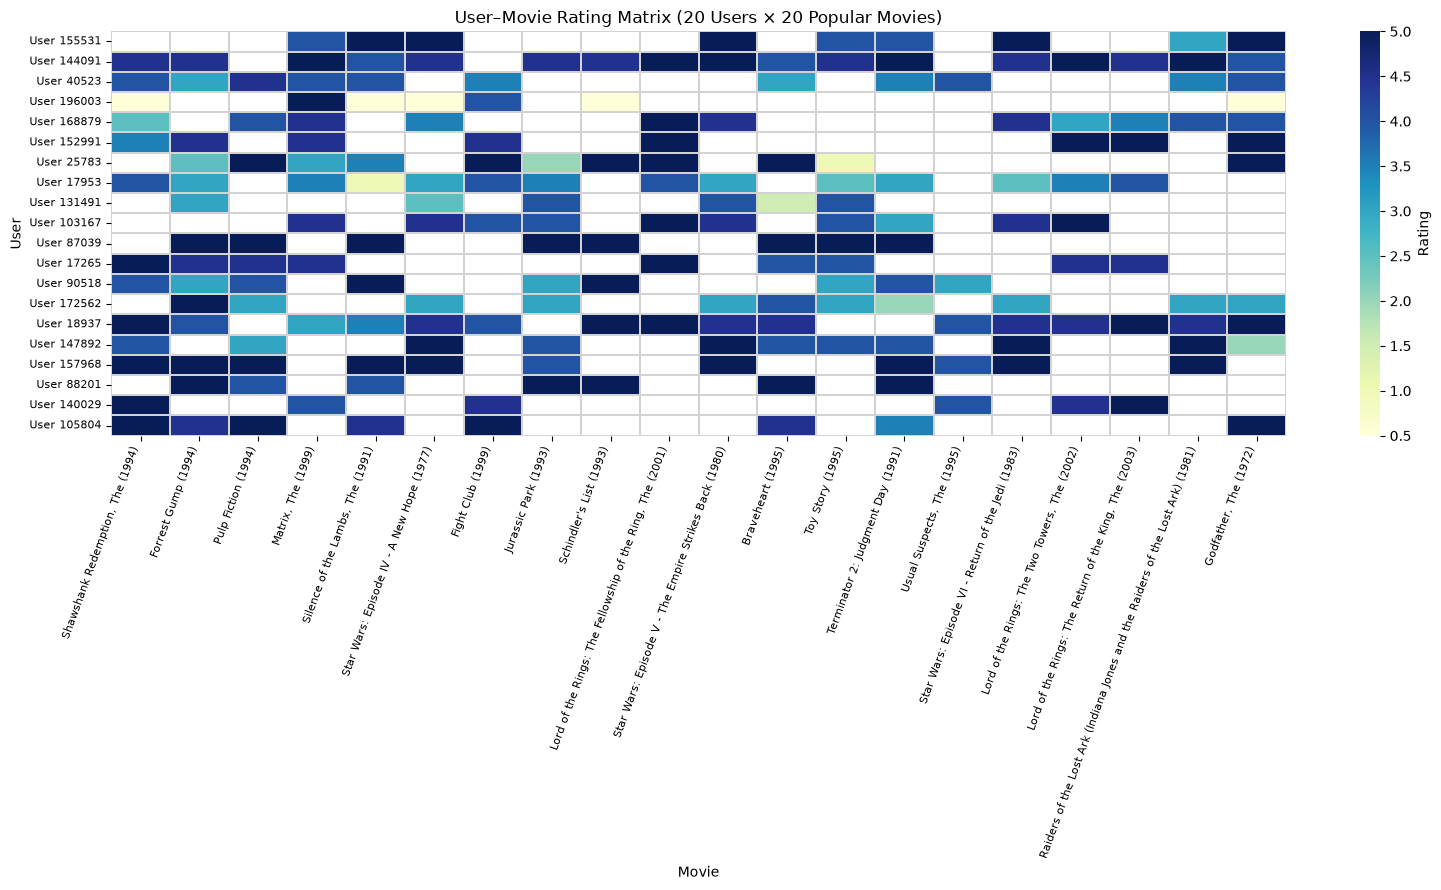

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Select the 20 most frequently rated movies
top_movies = ratings["movieId"].value_counts().head(20).index.to_numpy()

# 2. Find users who rated at least 5 of these movies
popular_ratings = ratings[ratings["movieId"].isin(top_movies)]
user_counts = popular_ratings.groupby("userId").size()
eligible_users = user_counts[user_counts >= 5].index.to_numpy()

# 3. Randomly sample 20 eligible users
rng = np.random.default_rng(42)
sample_users = rng.choice(
    eligible_users,
    size=min(20, len(eligible_users)),
    replace=False
)

# 4. Extract the corresponding submatrix
user_indices = [user_to_idx[u] for u in sample_users]
movie_indices = [movie_to_idx[m] for m in top_movies]

sample_ratings = rating_matrix[user_indices, :][:, movie_indices].toarray()
sample_ratings[sample_ratings == 0] = np.nan

# 5. Convert movie IDs to titles
movie_title_map = movies.set_index("movieId")["title"]
sample_titles = [
    movie_title_map.get(mid, str(mid))
    for mid in top_movies
]

rating_df = pd.DataFrame(
    sample_ratings,
    index=[f"User {u}" for u in sample_users],
    columns=sample_titles
)

# 6. Plot the heatmap
plt.figure(figsize=(16, 9))

sns.heatmap(
    rating_df,
    cmap="YlGnBu",
    vmin=0.5,
    vmax=5,
    linewidths=0.3,
    linecolor="lightgray",
    mask=rating_df.isna(),
    cbar_kws={"label": "Rating"}
)

plt.title("User–Movie Rating Matrix (20 Users × 20 Popular Movies)")
plt.xlabel("Movie")
plt.ylabel("User")
plt.xticks(rotation=70, ha="right", fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

In [27]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Map movie IDs to their titles
movie_title_map = movies.set_index("movieId")["title"]

# Reverse the movie index mapping
idx_to_movie = {idx: movie_id for movie_id, idx in movie_to_idx.items()}

def recommend_by_ratings(movie_titles, top_n=10):
    # Find the matrix indices of the input movies
    selected_indices = []

    for title in movie_titles:
        matches = movies.loc[
            movies["title"].str.casefold() == title.casefold(),
            "movieId"
        ]

        if matches.empty:
            raise ValueError(f"Movie not found: {title}")

        movie_id = matches.iloc[0]

        if movie_id not in movie_to_idx:
            raise ValueError(f"No ratings available for: {title}")

        selected_indices.append(movie_to_idx[movie_id])

    # Get the user-rating vectors for the selected movies
    selected_vectors = movie_user_matrix[selected_indices]

    # Calculate similarities only between selected movies and all movies
    similarities = cosine_similarity(
        selected_vectors,
        movie_user_matrix
    )

    # Average similarity across the input movies
    mean_similarity = similarities.mean(axis=0)

    # Exclude the input movies from recommendations
    mean_similarity[selected_indices] = -1

    # Get the top recommendations
    top_indices = np.argsort(mean_similarity)[::-1][:top_n]
    recommended_ids = [idx_to_movie[i] for i in top_indices]

    result = movies.set_index("movieId").loc[
        recommended_ids, ["title", "genres"]
    ].copy()

    result["similarity"] = mean_similarity[top_indices]

    return result.reset_index()

In [28]:
# Transpose the user-rating matrix
# Original: rows = users, columns = movies
# Transposed: rows = movies, columns = users

movie_user_matrix = rating_matrix.T.tocsr()

print("Movie-user matrix shape:", movie_user_matrix.shape)
print("Matrix type:", type(movie_user_matrix))

Movie-user matrix shape: (84432, 200948)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


### 3.2.3 SVD-based Similarity

The third method uses the latent factor representations learned by the SVD model introduced in the rating prediction section.

During training, SVD represents each user and each movie using a lower-dimensional vector of latent factors. These factors are learned from the observed ratings and help the model capture patterns in user–movie interactions. In this project, each movie is represented by its learned latent factor vector.

We calculate cosine similarity between these movie vectors to identify movies with similar latent representations. Unlike genre-based similarity, these representations are not defined by explicit categories. Unlike rating-based similarity, they do not directly compare the original rating vectors.

It is important to note that the SVD model is trained to predict ratings, not to directly optimise movie-to-movie similarity. Therefore, the resulting recommendations are an exploratory use of the learned representations, and high similarity does not necessarily imply that two movies have similar genres or storylines.

In [29]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import pandas as pd
# Extract the learned latent factors for all movies
movie_ids_svd = svd_model.trainset.all_items()
movie_factors = np.array([    
svd_model.qi[i]    
for i in movie_ids_svd
])
movie_ids_original = [    
svd_model.trainset.to_raw_iid(i)    
for i in movie_ids_svd
]
# Normalize movie vectors without constructing a full similarity matrix
norms = np.linalg.norm(movie_factors, axis=1, keepdims=True)
movie_factors_norm = movie_factors / np.maximum(norms, 1e-12)
movie_id_to_idx = {
    movie_id: idx    
for idx, movie_id in enumerate(movie_ids_original)
}

def recommend_svd(movie_titles, top_n=10):
    if top_n < 1:
        raise ValueError("top_n must be at least 1")

    # Find the three input movies
    input_ids = []
    input_titles = []

    for title in movie_titles:
        exact_matches = movies[
            movies["title"].str.casefold() == title.casefold()
        ]

        if not exact_matches.empty:
            match = exact_matches.iloc[0]
        else:
            matches = movies[
                movies["title"].str.contains(
                    title, case=False, regex=False, na=False
                )
            ]

            if matches.empty:
                return f"No movie found matching: {title}"

            if len(matches) > 1:
                return (
                    f"Multiple movies found matching '{title}'. "
                    "Please use a more specific title:\n"
                    + "\n".join(matches["title"].head(10).tolist())
                )

            match = matches.iloc[0]

        movie_id = match["movieId"]

        if movie_id not in movie_id_to_idx:
            return f"{match['title']} is not in the trained SVD model."

        if movie_id not in input_ids:
            input_ids.append(movie_id)
            input_titles.append(match["title"])

    if not input_ids:
        return "Please provide at least one valid input movie."

    # Get the latent-vector indices of the input movies
    input_indices = [
        movie_id_to_idx[movie_id] for movie_id in input_ids
    ]

    # Calculate similarity to each input movie, then average
    similarity_scores = movie_factors_norm @ (
        movie_factors_norm[input_indices].T
    )
    scores = similarity_scores.mean(axis=1)

    # Exclude all input movies from the recommendations
    scores[input_indices] = -np.inf

    # Select the top recommendations
    top_indices = np.argsort(scores)[::-1][:top_n]

    results = pd.DataFrame({
        "movieId": [movie_ids_original[i] for i in top_indices],
        "svd_similarity": scores[top_indices]
    })

    results = results.merge(
        movies[["movieId", "title", "genres"]],
        on="movieId",
        how="left"
    )

    return results[["title", "genres", "svd_similarity"]]


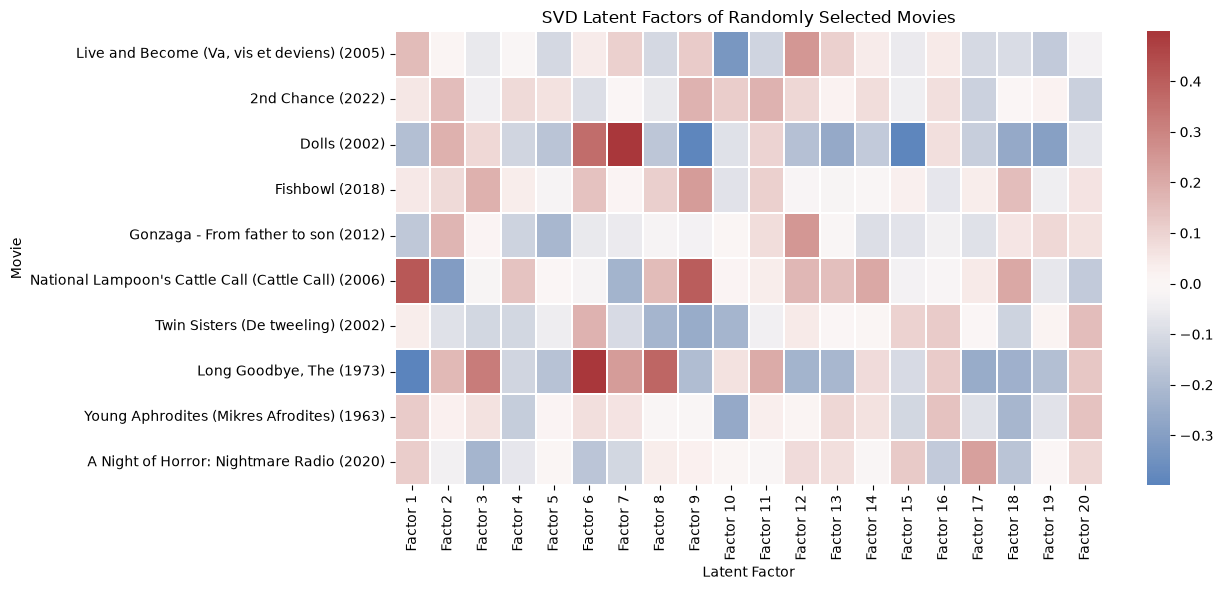

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Randomly select 10 movies
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(movie_ids_original),
    size=min(10, len(movie_ids_original)),
    replace=False
)

sample_factors = movie_factors[sample_indices]

sample_titles = [
    movies.loc[
        movies["movieId"] == movie_ids_original[idx], "title"
    ].iloc[0]
    for idx in sample_indices
]

factor_df = pd.DataFrame(
    sample_factors,
    index=sample_titles,
    columns=[f"Factor {i}" for i in range(1, movie_factors.shape[1] + 1)]
)

plt.figure(figsize=(13, 6))
sns.heatmap(
    factor_df,
    cmap="vlag",
    center=0,
    linewidths=0.3
)
plt.title("SVD Latent Factors of Randomly Selected Movies")
plt.xlabel("Latent Factor")
plt.ylabel("Movie")
plt.tight_layout()
plt.show()

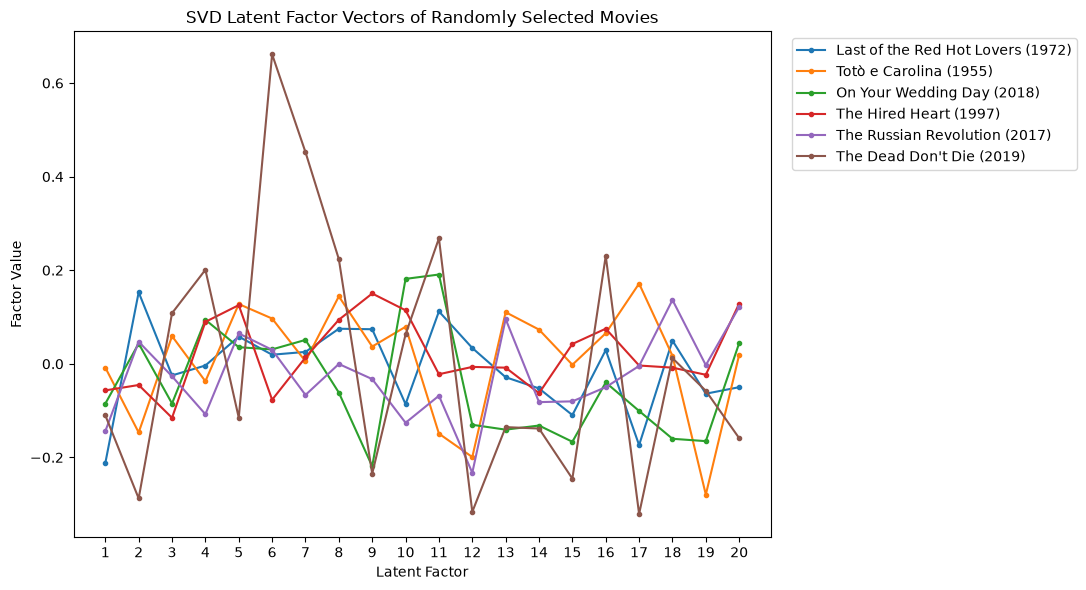

In [31]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Randomly select 6 movies from the trained SVD model
rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(movie_ids_original),
    size=min(6, len(movie_ids_original)),
    replace=False
)

plt.figure(figsize=(11, 6))

for idx in sample_indices:
    plt.plot(
        range(1, movie_factors.shape[1] + 1),
        movie_factors[idx],
        marker="o",
        markersize=3,
        label=movies.loc[
            movies["movieId"] == movie_ids_original[idx], "title"
        ].iloc[0]
    )

plt.xlabel("Latent Factor")
plt.ylabel("Factor Value")
plt.title("SVD Latent Factor Vectors of Randomly Selected Movies")
plt.xticks(range(1, movie_factors.shape[1] + 1))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 3.3 Results

To compare the three recommendation methods, we selected three input movies: *2001: A Space Odyssey (1968)*, *Inception (2010)*, and *Blade Runner (1982)*. These are films that I personally enjoy, making them a natural starting point for exploring what other movies each method considers similar.

The titles were first searched in the MovieLens dataset to identify the corresponding movie IDs and genre labels. We then used the three movies as input to all three recommendation methods: genre-based similarity, rating-based similarity, and SVD-based similarity. Each method produced a ranked list of similar movies.

The choice of input movies is subjective, but the approach is not limited to this particular selection. MovieLens contains nearly 90,000 movies, allowing users to replace the input titles with other movies in the dataset and explore recommendations based on their own interests. This flexibility makes the methods useful for investigating how different representations of movies lead to different recommendations.

The following results compare the recommendations produced by the three methods using the same input movies.

In [32]:
movies_rec[
    movies_rec["title"].str.contains(
        r"A Space Odyssey|Inception|Blade Runner",
        case=False,
        na=False
    )
][["movieId", "title", "genres"]].head(20)

,movieId,title,genres
536,541,Blade Runner (1982),Action|Sci-Fi|Thriller
903,924,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi
14939,79132,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX
39616,156771,Dangerous Days: Making Blade Runner (2007),Documentary
48841,176371,Blade Runner 2049 (2017),Sci-Fi
50015,178907,Blade Runner: Black Out 2022 (2017),Action|Animation|Sci-Fi
52911,184943,Oscar Pistorius: Blade Runner Killer (2017),Drama
76839,254592,On the Edge of 'Blade Runner' (2000),Documentary


In [33]:
recommend_movies(
    [
        "2001: A Space Odyssey (1968)",
        "Inception (2010)",
        "Blade Runner (1982)"
    ],
    top_n=10
)

,movieId,title,genres,similarity
0,8361,"Day After Tomorrow, The (2004)",Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
1,27618,"Sound of Thunder, A (2005)",Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
2,251662,Awake (2021),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
3,48774,Children of Men (2006),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
4,141385,Humanity's End (2009),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
5,91500,The Hunger Games (2012),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
6,117529,Jurassic World (2015),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
7,187031,Jurassic World: Fallen Kingdom (2018),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
8,58025,Jumper (2008),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772
9,191221,Toxic Skies (2008),Action|Adventure|Drama|Sci-Fi|Thriller,0.741772


In [34]:
recommend_by_ratings(
    ["Inception (2010)", "Blade Runner (1982)", "2001: A Space Odyssey (1968)"],
    top_n=10
)

,movieId,title,genres,similarity
0,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,0.521355
1,1214,Alien (1979),Horror|Sci-Fi,0.508846
2,1196,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Sci-Fi,0.494877
3,2959,Fight Club (1999),Action|Crime|Drama|Thriller,0.483103
4,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,0.481360
5,1206,"Clockwork Orange, A (1971)",Crime|Drama|Sci-Fi|Thriller,0.477303
6,1240,"Terminator, The (1984)",Action|Sci-Fi|Thriller,0.466181
7,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,0.464860
8,1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi,0.463779
9,1198,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure,0.461691


In [35]:

# Input movies
input_movies = [
    "Inception (2010)",
    "Blade Runner (1982)",
    "2001: A Space Odyssey (1968)"
]

# Get SVD-based recommendations
svd_recommendations = recommend_svd(
    input_movies,
    top_n=10
)

svd_recommendations


,title,genres,svd_similarity
0,I Shall Not Be Removed: The Life of Marlon Rig...,Documentary,0.590837
1,Apocalypse Now (1979),Action|Drama|War,0.589412
2,Once Upon a Time in the West (C'era una volta ...,Action|Drama|Western,0.567408
3,How to Die in Oregon (2011),Documentary|Drama,0.566757
4,Unforgiven (1992),Drama|Western,0.559861
5,"Tale of Zatoichi Continues, The (Zoku Zatôichi...",Action|Drama,0.552718
6,"Unforgiven, The (1960)",Drama|Western,0.548823
7,Beware of Mr. Baker (2012),Documentary,0.547510
8,Full Metal Jacket (1987),Drama|War,0.544253
9,Blade Runner 2049 (2017),Sci-Fi,0.535628


### Comparing the Recommendation Methods

Evaluating movie recommendations is not straightforward, since relevance and similarity are inherently subjective. A recommendation that seems obvious to one viewer may be completely uninteresting to another. Without explicit preference data or a defined evaluation criterion, it is difficult to determine which method produces the most accurate recommendations in an objective sense. Instead, I compare the results qualitatively, drawing on my own experience as a movie viewer.

The genre-based method tends to produce relatively coarse recommendations. For example, science-fiction films may be grouped together because they share the same genre labels, even when their styles, themes, or overall viewing experiences differ considerably.

The rating-based method produces recommendations that often feel more mainstream and familiar. Given the large number of ratings in MovieLens 32M, the model has access to extensive information about users' rating patterns. Its recommendations appear broadly plausible, although familiarity alone does not establish that they are the best match for an individual viewer.

The SVD-based method has been the most surprising. In my initial experiment, it recommended *I Shall Not Be Removed*, a documentary I had never seen. Some of its recommendations appear less obvious and more obscure than those produced by the other methods. Since the latent factors are learned from rating data and do not have directly interpretable meanings, it is difficult to explain precisely why these particular movies are considered similar. Nevertheless, this unexpected behaviour makes the method especially interesting to explore.

These observations motivated a second experiment using a different set of input movies: *Inland Empire* (2006), *3 Women* (1977), and *Inherent Vice* (2014). By changing the input, I can investigate whether the three methods continue to differ in similar ways, and whether the SVD-based method produces further unexpected recommendations.

These comparisons are exploratory rather than a formal evaluation of recommendation accuracy. The results reflect one viewer's interpretation of the recommendations and should not be generalised to all users.

In [36]:
movies_rec[
    movies_rec["title"].str.contains(
        r"Inland Empire|3 Women|Inherent Vice",
        case=False,
        na=False
    )
][["movieId", "title", "genres"]]

,movieId,title,genres
7702,8261,3 Women (Three Women) (1977),Drama
11278,49932,Inland Empire (2006),Drama|Mystery|Thriller
23026,116799,Inherent Vice (2014),Comedy|Crime|Drama|Mystery|Romance
76066,251190,3 Women (2020),(no genres listed)


In [39]:
recommend_movies(    
[        
"3 Women (Three Women) (1977)",        
"Inland Empire (2006)",        
"Inherent Vice (2014)"    
],
    top_n=10
)

,movieId,title,genres,similarity
0,187089,The Bottomless Bag (2017),Drama|Mystery,0.718686
1,2749,"Morning After, The (1986)",Drama|Mystery,0.718686
2,210223,Agnes Cecilia - En sällsam historia (1991),Drama|Mystery,0.718686
3,43538,Rampo (a.k.a. The Mystery of Rampo) (1994),Drama|Mystery,0.718686
4,248260,Spreading Ground (2000),Drama|Mystery,0.718686
5,286685,The Other Side (2020),Drama|Mystery,0.718686
6,1964,Klute (1971),Drama|Mystery,0.718686
7,248844,The Sounding (2017),Drama|Mystery,0.718686
8,248784,"Like Mother, Like Daughter (2007)",Drama|Mystery,0.718686
9,176903,Demimonde (2015),Drama|Mystery,0.718686


In [40]:
recommend_by_ratings(    
["3 Women (Three Women) (1977)",        
"Inland Empire (2006)",        
"Inherent Vice (2014)"  ],
    top_n=10
)

,movieId,title,genres,similarity
0,96728,"Master, The (2012)",Drama,0.270855
1,7044,Wild at Heart (1990),Crime|Drama|Mystery|Romance|Thriller,0.247181
2,3676,Eraserhead (1977),Drama|Horror,0.242835
3,62511,"Synecdoche, New York (2008)",Comedy|Drama,0.238933
4,1464,Lost Highway (1997),Crime|Drama|Fantasy|Film-Noir|Mystery|Romance,0.237612
5,7327,Persona (1966),Drama,0.236653
6,106766,Inside Llewyn Davis (2013),Drama,0.227516
7,6774,Videodrome (1983),Fantasy|Horror|Sci-Fi|Thriller,0.226391
8,7071,"Woman Under the Influence, A (1974)",Drama,0.225117
9,71464,"Serious Man, A (2009)",Comedy|Drama,0.223917


In [41]:
input_movies = [  "3 Women (Three Women) (1977)",        
"Inland Empire (2006)",        
"Inherent Vice (2014)"    

]

svd_recommendations = recommend_svd(
    input_movies,
    top_n=10
)
svd_recommendations

,title,genres,svd_similarity
0,"Master, The (2012)",Drama,0.830829
1,Li'l Quinquin (2014),Comedy|Crime|Mystery,0.825547
2,Mulholland Drive (2001),Crime|Drama|Film-Noir|Mystery|Thriller,0.806653
3,"Circle, The (Dayereh) (2000)",Drama,0.803091
4,Cure (1997),Crime|Horror|Thriller,0.801490
5,Old Joy (2006),Drama,0.797363
6,Time Out (L'emploi du temps) (2001),Drama,0.795957
7,He Died With a Felafel in His Hand (2001),Comedy,0.791442
8,Videodrome (1983),Fantasy|Horror|Sci-Fi|Thriller,0.790804
9,Warm Water Under a Red Bridge (Akai hashi no s...,Comedy|Drama,0.788300


#### Summary of the Results

The three methods produce noticeably different types of recommendations. The genre-based method is simple and interpretable, but its predefined categories are relatively coarse and often cannot distinguish between movies that share the same genre labels. The rating-based method makes use of much richer information from user behaviour and tends to produce more familiar and broadly plausible recommendations, but its performance can become less reliable for movies with relatively few ratings because of the sparsity of the rating matrix.

The SVD-based method produces the most interesting results when the movies become more obscure. Instead of simply grouping movies by genre or relying on a large number of overlapping user ratings, SVD uses learned latent representations to capture patterns in the full rating dataset. This can lead to unexpected recommendations that are difficult to explain directly, but can nevertheless make intuitive sense from a human perspective. For example, movies such as *Mulholland Drive*, *Cure*, *Old Joy*, and *Videodrome* appeared among the recommendations despite not being obvious matches based on their genre labels alone.

The latent factors themselves are not directly interpretable, so we cannot determine exactly what specific characteristics cause two movies to be close in the learned representation. Nevertheless, this is also what makes the SVD-based approach interesting: it can reveal associations that are difficult to obtain from predefined genres or sparse raw rating patterns.

Overall, the experiment illustrates a trade-off between interpretability, data sparsity, and the ability to discover less obvious relationships. Rather than identifying one universally best recommendation method, the three approaches provide different perspectives on what it means for two movies to be similar.

### delete this part before pre
 more tests from my firends

In [42]:
movies_rec[
    movies_rec["title"].str.contains(
        r"cold fish|Narnia|interstellar",
        case=False,
        na=False
    )
][["movieId", "title", "genres"]]

,movieId,title,genres
10452,41566,"Chronicles of Narnia: The Lion, the Witch and ...",Adventure|Children|Fantasy
12349,59501,"Chronicles of Narnia: Prince Caspian, The (2008)",Adventure|Children|Fantasy
15613,82169,Chronicles of Narnia: The Voyage of the Dawn T...,Adventure|Children|Fantasy
17033,89582,Cold Fish (Tsumetai nettaigyo) (2010),Drama|Thriller
21207,109487,Interstellar (2014),Sci-Fi|IMAX
53050,185231,"The Chronicles of Narnia: The Lion, the Witch ...",Adventure|Children|Fantasy
61860,204120,The Science of Interstellar (2014),Documentary


In [44]:
recommend_by_ratings(    
["Chronicles of Narnia: Prince Caspian, The (2008)",        
"Cold Fish (Tsumetai nettaigyo) (2010)",        
"Interstellar (2014)"  ],
    top_n=10
)

,movieId,title,genres,similarity
0,79132,Inception (2010),Action|Crime|Drama|Mystery|Sci-Fi|Thriller|IMAX,0.302654
1,134130,The Martian (2015),Adventure|Drama|Sci-Fi,0.290986
2,91529,"Dark Knight Rises, The (2012)",Action|Adventure|Crime|IMAX,0.276767
3,112852,Guardians of the Galaxy (2014),Action|Adventure|Sci-Fi,0.275992
4,58559,"Dark Knight, The (2008)",Action|Crime|Drama|IMAX,0.275567
5,111759,Edge of Tomorrow (2014),Action|Sci-Fi|IMAX,0.269340
6,99114,Django Unchained (2012),Action|Drama|Western,0.264860
7,72998,Avatar (2009),Action|Adventure|Sci-Fi|IMAX,0.264812
8,115713,Ex Machina (2015),Drama|Sci-Fi|Thriller,0.262056
9,89745,"Avengers, The (2012)",Action|Adventure|Sci-Fi|IMAX,0.260402


In [45]:
input_movies = ["Chronicles of Narnia: Prince Caspian, The (2008)",        
"Cold Fish (Tsumetai nettaigyo) (2010)",        
"Interstellar (2014)"    

]

svd_recommendations = recommend_svd(
    input_movies,
    top_n=10
)
svd_recommendations

,title,genres,svd_similarity
0,Beijing Rocks (2001),Drama,0.330933
1,One Winter Proposal (2019),Romance,0.322432
2,The Fjällbacka Murders: Friends for Life (2013),Crime|Mystery,0.308801
3,The Shadow (1933),Mystery,0.304713
4,Hindsight (2011),Action|Crime|Romance,0.303082
5,The Farmer (1977),Action,0.302199
6,Jaurès (2012),(no genres listed),0.301705
7,Darling (2010),Drama|Romance,0.300336
8,After All These Years (2013),Mystery,0.298878
9,Blue Seduction (2009),Romance|Thriller,0.298531


In [63]:
input_movies = ["Fear and Loathing in Las Vegas (1998)",        
"Easy Rider (1969)",        
"Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966)"    
]
svd_recommendations = recommend_svd(
    input_movies,
    top_n=10
)
svd_recommendations

,title,genres,svd_similarity
0,Ziggy Stardust and the Spiders from Mars (1973),Documentary|Musical,0.719251
1,Apocalypse Now (1979),Action|Drama|War,0.714718
2,Full Metal Jacket (1987),Drama|War,0.707733
3,High School (1968),Documentary,0.698511
4,"Duck, You Sucker (1971)",Action|Western,0.694589
5,Wild at Heart (1990),Crime|Drama|Mystery|Romance|Thriller,0.689971
6,Lolita (1962),Drama|Romance,0.687806
7,Once Upon a Time in the West (C'era una volta ...,Action|Drama|Western,0.679058
8,Withnail & I (1987),Comedy,0.678863
9,"Clockwork Orange, A (1971)",Crime|Drama|Sci-Fi|Thriller,0.676674


In [64]:
recommend_by_ratings(    
["Fear and Loathing in Las Vegas (1998)",        
"Easy Rider (1969)",        
"Good, the Bad and the Ugly, The (Buono, il brutto, il cattivo, Il) (1966)"  ],
    top_n=10
)

,movieId,title,genres,similarity
0,1208,Apocalypse Now (1979),Action|Drama|War,0.375301
1,1222,Full Metal Jacket (1987),Drama|War,0.369673
2,1206,"Clockwork Orange, A (1971)",Crime|Drama|Sci-Fi|Thriller,0.364040
3,1732,"Big Lebowski, The (1998)",Comedy|Crime,0.363700
4,1089,Reservoir Dogs (1992),Crime|Mystery|Thriller,0.353608
5,2951,"Fistful of Dollars, A (Per un pugno di dollari...",Action|Western,0.350857
6,924,2001: A Space Odyssey (1968),Adventure|Drama|Sci-Fi,0.344255
7,1258,"Shining, The (1980)",Horror,0.343064
8,750,Dr. Strangelove or: How I Learned to Stop Worr...,Comedy|War,0.340961
9,111,Taxi Driver (1976),Crime|Drama|Thriller,0.337125


In [65]:
recommend_by_ratings(    
["Mysterious Skin (2004)",        
"Cruising (1980)",        
"The Batman (2022)"  ],
    top_n=10
)

,movieId,title,genres,similarity
0,263007,Spider-Man: No Way Home (2021),Action|Adventure|Fantasy|Sci-Fi,0.212183
1,254726,Dune (2021),Action|Adventure|Drama|Sci-Fi,0.204767
2,270698,Everything Everywhere All at Once (2022),Action|Comedy|Sci-Fi,0.198470
3,274053,Top Gun: Maverick (2022),Action|Drama,0.177939
4,272525,Doctor Strange in the Multiverse of Madness (2...,Action|Adventure|Fantasy,0.174155
5,244178,The Northman,Adventure|Drama|Thriller,0.169498
6,251086,The Suicide Squad (2021),Action|Adventure|Crime|Fantasy,0.168156
7,273891,Bullet Train (2022),Action|Mystery|Thriller,0.159108
8,224280,No Time to Die (2020),Action|Adventure|Mystery|Thriller,0.158653
9,278702,Glass Onion: A Knives Out Mystery (2022),Comedy|Crime|Mystery,0.157434


In [66]:
input_movies = ["Mysterious Skin (2004)",        
"Cruising (1980)",        
"The Batman (2022)"   
]
svd_recommendations = recommend_svd(
    input_movies,
    top_n=10
)
svd_recommendations

,title,genres,svd_similarity
0,"War Zone, The (1999)",Drama|Thriller,0.532123
1,Possessor (2020),Horror|Sci-Fi|Thriller,0.523510
2,Ping Pong (2002),Comedy|Drama,0.515914
3,Annihilation (2018),Adventure|Mystery|Sci-Fi|Thriller,0.508340
4,Nekromantik (1987),Comedy|Horror,0.505589
5,The Girls (1968),Comedy,0.504839
6,Bunny Lake Is Missing (1965),Mystery|Thriller,0.502755
7,Cirque Du Soleil: Kooza (2008),Documentary,0.502629
8,Kubrick Remembered (2014),Documentary,0.502246
9,Crimes of the Future (2022),Drama|Horror|Sci-Fi,0.501955


# 4. Discussion and Conclusion

I invited several friends to test the recommendation system with many different combinations of movies. The individual test cases are not listed here, but the experiments revealed several clear differences between the three methods.

When the three input movies had very different genres, the genre-based method became almost useless because it had very little information to identify a common preference. When the three movies differed greatly in popularity, the rating-based method tended to be dominated by the most popular movie, since it has much more rating data available. The SVD-based method did not show these problems as clearly. Its latent factors provided a more balanced representation, while also producing some unexpected recommendations that could not be easily explained by genres or direct rating similarity.

The recommendation results were evaluated qualitatively rather than with a numerical metric. This is partly because recommendation is subjective: a higher similarity score does not necessarily mean that a recommendation is better. It is also computationally convenient, since we only need to calculate similarities for the selected input movies rather than constructing a complete similarity matrix for all nearly 90,000 movies.

One possible extension would be to use neural networks to learn more complex relationships between movies. I considered this approach, but did not implement it because of the limited time and computational resources available for this project. I may also develop the recommendation system into a lightweight interactive website in the future, although this is beyond the scope of the current course project.

Overall, this project shows that different representations of movies lead to very different recommendations. There is no single definition of movie similarity: genres, user behaviour, and learned latent factors each reveal a different aspect of the relationships within the MovieLens dataset.